In [2]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [3]:
class BatsmanState(TypedDict):
    runs : int
    balls : int
    fours : int
    sixes : int

    sr : int
    bpb : int
    boundary_percent : float

    summary : str
    


In [12]:
def calculate_st(state : BatsmanState) -> dict:
    sr = (state['runs']/state['balls']) * 100
    return {'sr' : sr}

def calculate_bpb(state : BatsmanState) -> dict:
    bpb = state['balls']/(state['fours'] + state['sixes'])
    return {'bpb':bpb}

def calculate_boundary_percent(state : BatsmanState) -> dict:
    boundary_percent = (((state['fours'] * 4) + (state['sixes'] * 6))/state['runs']) *100
    return {'boundary_percent':boundary_percent}

def calculate_summary(state : BatsmanState) -> dict:
    summary = f"""
    Strike Rate - {state['sr']} \n
    Balls per boundary - {state['bpb']} \n
    Boundary percent - {state['boundary_percent']}
    """
    return {'summary':summary}

In [13]:
graph = StateGraph(BatsmanState)

# add graph
graph.add_node('calculate_st', calculate_st)
graph.add_node('calculate_bpb',calculate_bpb)
graph.add_node('calculate_boundary_percent',calculate_boundary_percent)
graph.add_node('calculate_summary',calculate_summary)

# add edge
graph.add_edge(START, 'calculate_st')
graph.add_edge(START, 'calculate_bpb')
graph.add_edge(START, 'calculate_boundary_percent')

graph.add_edge('calculate_st','calculate_summary')
graph.add_edge('calculate_bpb','calculate_summary')
graph.add_edge('calculate_boundary_percent','calculate_summary')

graph.add_edge('calculate_summary', END)

workflow = graph.compile()




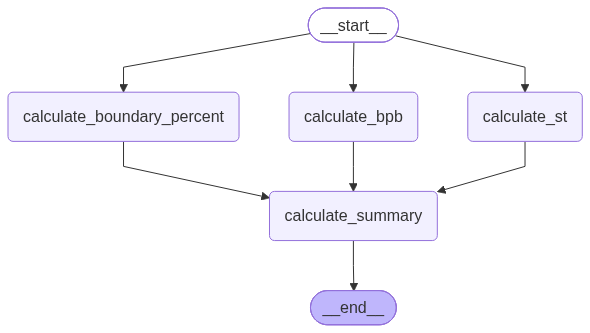

In [10]:
graph.compile()

in parallel workflow, there is a problem., we are sending whole state to all the three functions, so langgraph consider that all the values are being modified of that state in above thrre functions, and langgraph does not allow to ingest the values which are modified into multiple states at the same time. Thus gives error

To solve this problem we will only send those values in output which is being modified in that particular function 

This is called partial update

In [14]:
# Execute
initial_state = {
    'runs':100,
    'balls':50,
    'fours':6,
    'sixes':4
} 

workflow.invoke(initial_state)

{'runs': 100,
 'balls': 50,
 'fours': 6,
 'sixes': 4,
 'sr': 200.0,
 'bpb': 5.0,
 'boundary_percent': 48.0,
 'summary': '\n    Strike Rate - 200.0 \n\n    Balls per boundary - 5.0 \n\n    Boundary percent - 48.0\n    '}